
# Lecture 27 — Handling Control Hazards

**Professor:** Dr. Janibul Bashir  
**Lecture:** [Stalling, Delayed Branching and Branch Prediction](https://youtu.be/79_7s0NJ0RA?utm_source=chatgpt.com)  
**Duration:** 1 hour 12 minutes

---

## 1. The Fundamental Problem: We Don't Know the Next PC

Recall our five-stage processor:

$$
IF \rightarrow ID \rightarrow EX \rightarrow MEM \rightarrow WB
$$

Consider these RISC-V instructions:

```asm
I1: add x3, x4, x5
I2: beq x1, x2, TARGET
I3: sub x6, x7, x8
I4: add x9, x10, x11

TARGET:
I12: add x13, x14, x15
```

The branch instruction `beq` means:

$$
\text{If }x1=x2,\quad PC\leftarrow TARGET
$$

Otherwise:

$$
PC\leftarrow PC+4
$$

So after I2, the correct next instruction is either I3 or I12.

But the branch decision is made in **EX**, not IF.

### Let's Dry-Run the Pipeline

| Cycle | IF | ID | EX | MEM |
|---|---|---|---|---|
| 1 | I1 | — | — | — |
| 2 | I2 | I1 | — | — |
| 3 | I3 | I2 | I1 | — |
| 4 | I4 | I3 | I2 (branch) | I1 |

At the end of cycle 4, I2 determines whether the branch is taken.

But look at the problem: **I3 and I4 are already in the pipeline.**

If the branch is taken, they are wrong-path instructions.

> 📌 **Control Hazard:** Uncertainty about the correct next instruction address interferes with instruction fetching and execution.

---

## 2. Solution 1 — Stall Until the Branch Is Resolved

The simplest solution is to stop fetching subsequent instructions while waiting for the branch decision.

### Pipeline Timing

| Cycle | Branch I2 | Instruction Fetch |
|---|---|---|
| 2 | IF | Fetch I2 |
| 3 | ID | Stall |
| 4 | EX | Stall |
| 5 | MEM | Fetch correct successor |

The branch resolves at the end of cycle 4, so fetch resumes in cycle 5.

Thus:

$$
\boxed{\text{Branch penalty}=2\text{ cycles}}
$$

This matches the five-stage, EX-resolution model used in Lecture 24.
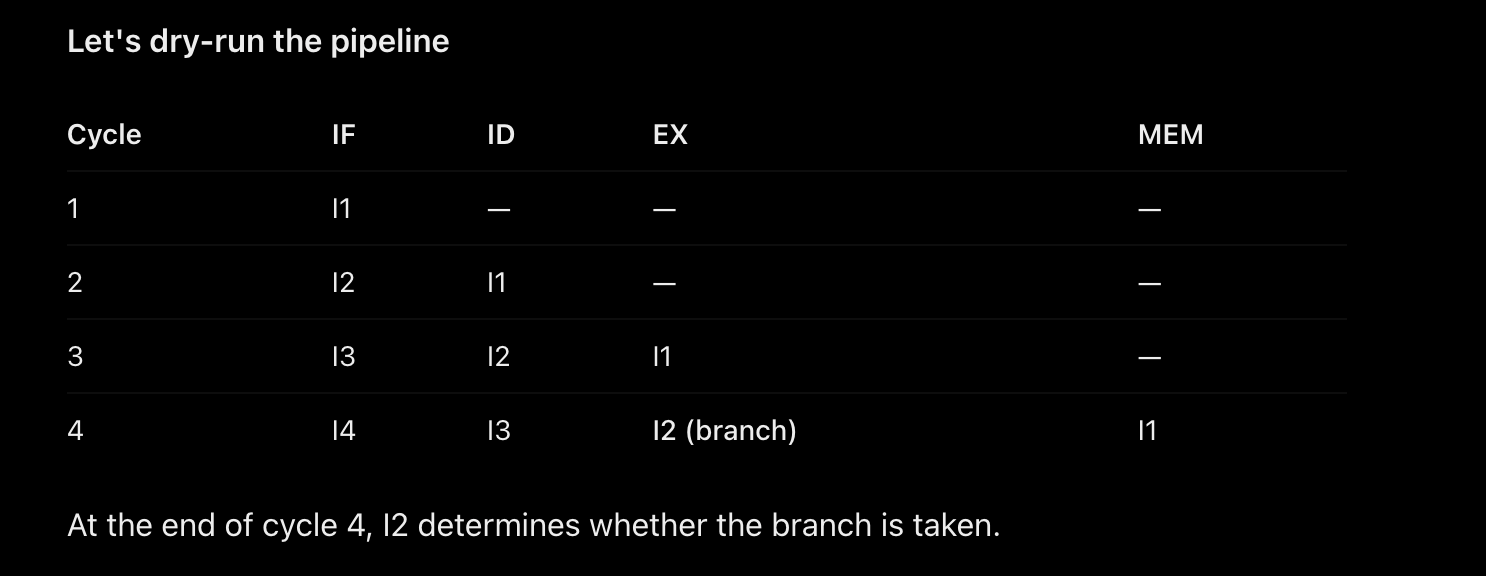
 

### Disadvantage

The processor loses **two instruction-fetch opportunities for every branch** it handles this way, even when the branch is not taken.

---

## 3. What the Actual Lecture 27 Video Covers

The direct-video analysis has now completed successfully.

It confirms the professor's sequence and provides the following timestamps:

| Video Timestamp | Topic |
|---|---|
| 0:00–7:15 | Conditional/unconditional and forward/backward branches |
| 7:16–21:14 | Pipeline control hazards and stalling |
| 21:15–35:15 | Delayed branching |
| 35:16–63:35 | Branch prediction, correct predictions and mispredictions |
| 63:36–72:07 | Static and dynamic branch predictors |

Let's continue with the two techniques introduced after stalling.

---

## 4. Solution 2 — Delayed Branching

**Professor's Video:** 21:15–35:15

Recall that stalling creates two unused instruction slots.

Instead of wasting them, can we execute something useful while the branch is being resolved?

That's the idea behind **delayed branching**.

### 4.1 Definition

> **Branch Delay Slot:** An instruction position immediately after a branch that is executed regardless of the branch outcome, under the delayed-branch architecture's rules.

### 4.2 Example

Suppose the original instructions are:

```asm
I1: add x8, x9, x10
I2: add x3, x4, x5
I3: beq x1, x2, TARGET
```

Assume I1 and I2 are independent of the branch and can be moved safely.

The compiler could rearrange them as:

```asm
I3: beq x1, x2, TARGET
I1: add x8, x9, x10
I2: add x3, x4, x5

TARGET:
...
```

For a hypothetical architecture with **two architecturally defined branch delay slots**, both I1 and I2 execute before the branch transfer takes effect.

### 4.3 Filling Two Delay Slots

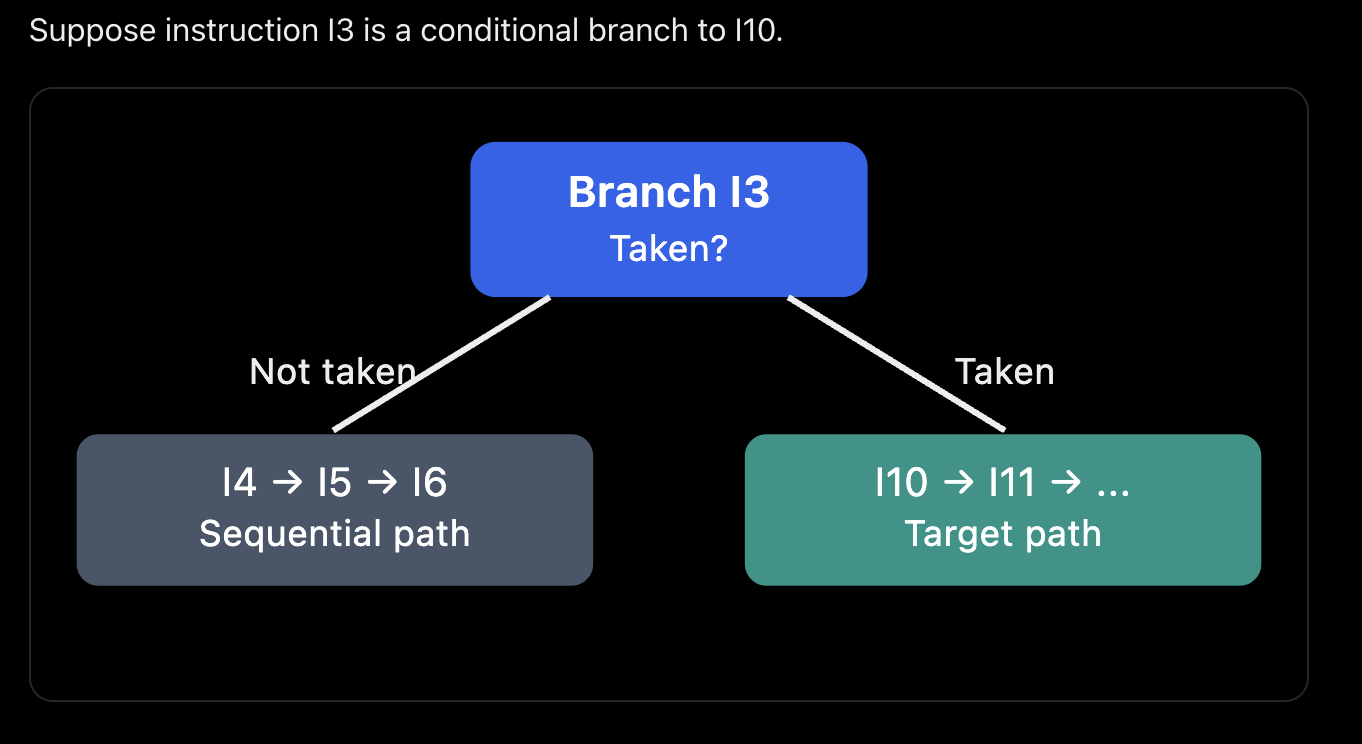
**Pipeline Stalling:**

```text
Branch
   ↓
Bubble
   ↓
Bubble
   ↓
Next instruction
```

**Delayed Branching:**

```text
Branch
   ↓
Useful I1
   ↓
Useful I2
   ↓
Next instruction
```

### 4.4 Why Is It Effective?

Instead of waiting two cycles:

- Cycle 1 after the branch: Execute useful instruction I1.
- Cycle 2 after the branch: Execute useful instruction I2.
- Then proceed from the resolved branch destination.

If both delay slots are filled safely, the effective wasted-cycle penalty can become **zero**.

However, the compiler must ensure that moving the instructions does not change program results.

A useful instruction must be safe on both possible branch outcomes, and its dependencies and side effects must be preserved.

> 📝 **Added note:** Standard RISC-V has no architectural branch-delay slots. The example explains the historical delayed-branching technique covered by the professor; it is not a recommended transformation of ordinary RISC-V code.

---

## 5. Solution 3 — Branch Prediction

**Professor's Video:** 35:16–63:35

Delayed branching still depends on finding suitable instructions.

So can the processor avoid waiting entirely?

**Yes — by predicting the branch outcome.**

### 5.1 Definition

> **Branch Prediction:** A hardware technique that predicts whether a branch will be taken and allows the processor to fetch instructions along the predicted path before the actual branch condition has been resolved.

### 5.2 Example From the Video

Suppose instruction I3 is a conditional branch to I10.

The predictor operates early enough to choose a likely next instruction.

If it predicts **Taken**, the processor starts fetching I10 instead of I4.

There are two possibilities.

### 5.3 Case A — Correct Prediction

The predictor says **Taken**, and the actual branch outcome is **Taken**.

| Cycle | Branch I3 | Instruction Fetch |
|---|---|---|
| 1 | IF | I3 |
| 2 | ID | I10 |
| 3 | EX | I11 |

The actual outcome is known after EX in cycle 3.

Since the predicted path was correct, I10 and I11 are valid instructions.

$$
\boxed{\text{Prediction penalty}=0\text{ cycles}}
$$

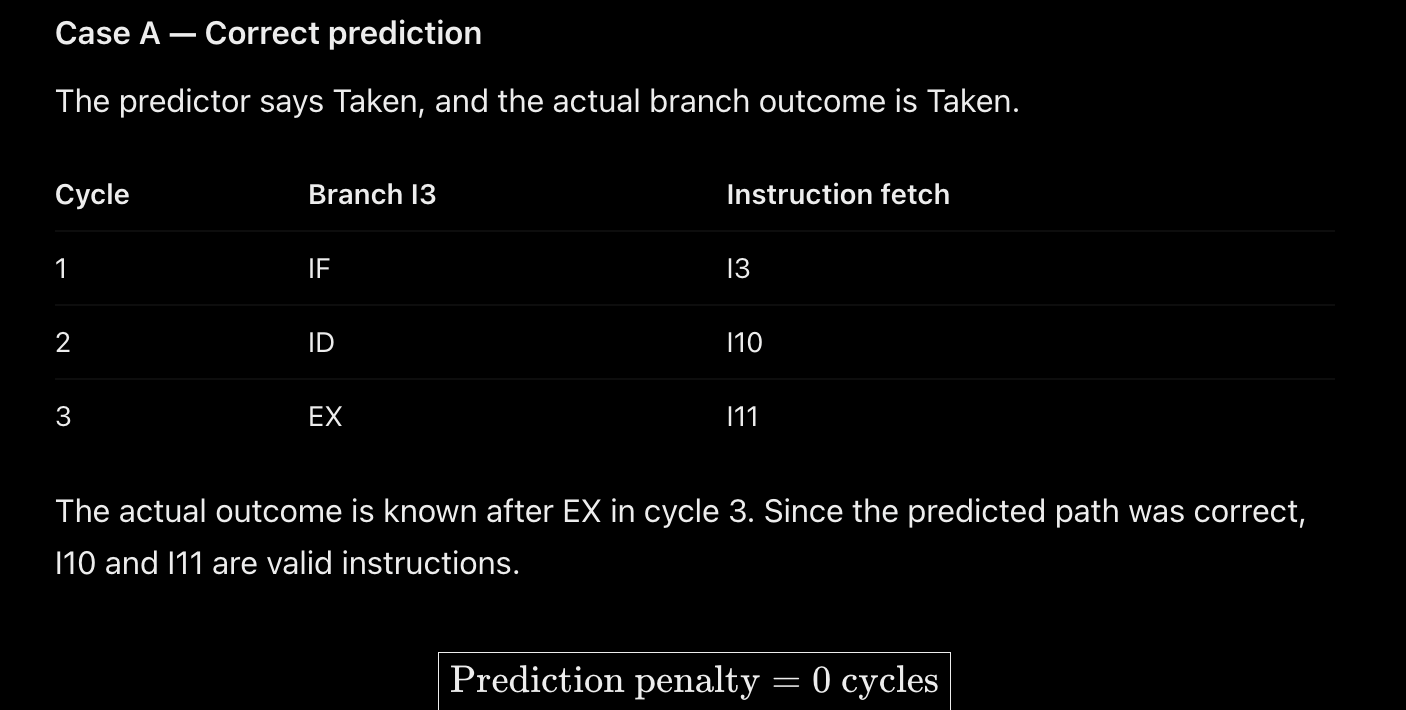
### 5.4 Case B — Incorrect Prediction

The predictor says **Taken**, but the actual outcome is **Not Taken**.

The processor has fetched I10 and I11, even though the correct successor should have been I4.

Those wrong-path instructions must be discarded.

This is called a **pipeline flush**.

The processor then restarts instruction fetching at the correct address.

In a simple five-stage pipeline resolving branches in EX, the resulting misprediction penalty can be approximately **two cycles**, although the exact cost depends on the design.


### 5.5 Comparison of Control-Hazard Solutions

| Technique | What Happens | Typical Penalty in Our Model |
|---|---|---|
| Stalling | Wait for branch outcome | 2 cycles |
| Delayed branching | Fill two delay slots with useful instructions | 0 if both safely filled |
| Correct prediction | Fetch correct path immediately | 0 cycles |
| Incorrect prediction | Flush wrong-path instructions | About 2 cycles |

---

## 6. Static vs Dynamic Branch Prediction

**Professor's Video:** 63:36–72:07

The video ends by classifying branch predictors.

### 6.1 Static Branch Prediction

Static branch prediction follows a predefined rule without adapting to runtime behavior.

The professor covers:

- **Always Taken**
- **Always Not Taken**
- **BTFN — Backward Taken, Forward Not Taken**

### Why Predict Backward Branches as Taken?

Because backward branches frequently implement loops that execute repeatedly.

### 6.2 Dynamic Branch Prediction

Dynamic branch prediction uses runtime branch behavior to make predictions.

The professor mentions:

- 1-bit predictors
- 2-bit predictors
- Saturating counters
- Global predictors
- TAGE
- Tournament predictors
- Hierarchical predictors

These are introduced as categories rather than fully derived circuit implementations in this lecture.

### 6.3 Static vs Dynamic — Key Difference

| Feature | Static Prediction | Dynamic Prediction |
|---|---|---|
| Prediction basis | Predefined rules | Runtime branch behavior |
| Adapts to execution history | No | Yes |
| Examples | Always Taken, Always Not Taken, BTFN | 1-bit, 2-bit, global, TAGE, tournament |

---

## 7. Performance Impact of Branch Prediction

For a long-running single-issue pipeline, a useful approximation is:

$$
\boxed{CPI\approx1+f_b\times r_m\times P_m}
$$

Where:

| Variable | Meaning |
|---|---|
| $f_b$ | Fraction of executed instructions that are branches |
| $r_m$ | Branch misprediction rate |
| $P_m$ | Penalty in cycles per misprediction |

> 📝 **Added note:** This is an additional useful performance model, not a formula specifically derived in the video analysis.

### 7.1 Numerical Example — With Branch Prediction

Suppose:

- 20% of instructions are branches.
- 10% of those branches are mispredicted.
- Each misprediction costs 2 cycles.

Therefore:

$$
CPI\approx1+(0.2)(0.1)(2)
$$

$$
\boxed{CPI\approx1.04}
$$

### 7.2 Numerical Example — Without Prediction

If the processor stalls two cycles for every branch:

$$
CPI\approx1+(0.2)(2)
$$

$$
\boxed{CPI\approx1.4}
$$

### 7.3 Final Comparison

| Approach | Average CPI |
|---|---|
| Stall for every branch | 1.40 |
| Branch prediction with 10% misprediction rate | **1.04** |

This demonstrates why effective branch prediction matters so much for processor performance.

---



# Lecture 27 — Part 4: Branch Prediction in Detail

**Professor:** Dr. Janibul Bashir  
**Source:** Lecture 27 direct-video analysis  
**Transcript Range:** Approximately 47:21–72:07

---

## 1. Understanding the Pipeline Flush

Consider:

```asm
I1: beq x5, x6, TARGET
I2: add x7, x8, x9
I3: sub x10, x11, x12

TARGET:
I10: add x13, x14, x15
I11: sub x16, x17, x18
```

Suppose the predictor says **Taken**, but the actual branch outcome is **Not Taken**.

The processor initially follows the target path.

### 1.1 Pipeline Execution

| Cycle | IF | ID | EX |
|---|---|---|---|
| 1 | I1 (branch) | — | — |
| 2 | I10 | I1 | — |
| 3 | I11 | I10 | I1: Not Taken |
| 4 | I2 | Bubble (flushed I11) | Bubble (flushed I10) |
| 5 | I3 | I2 | Bubble |
| 6 | Next | I3 | I2 |

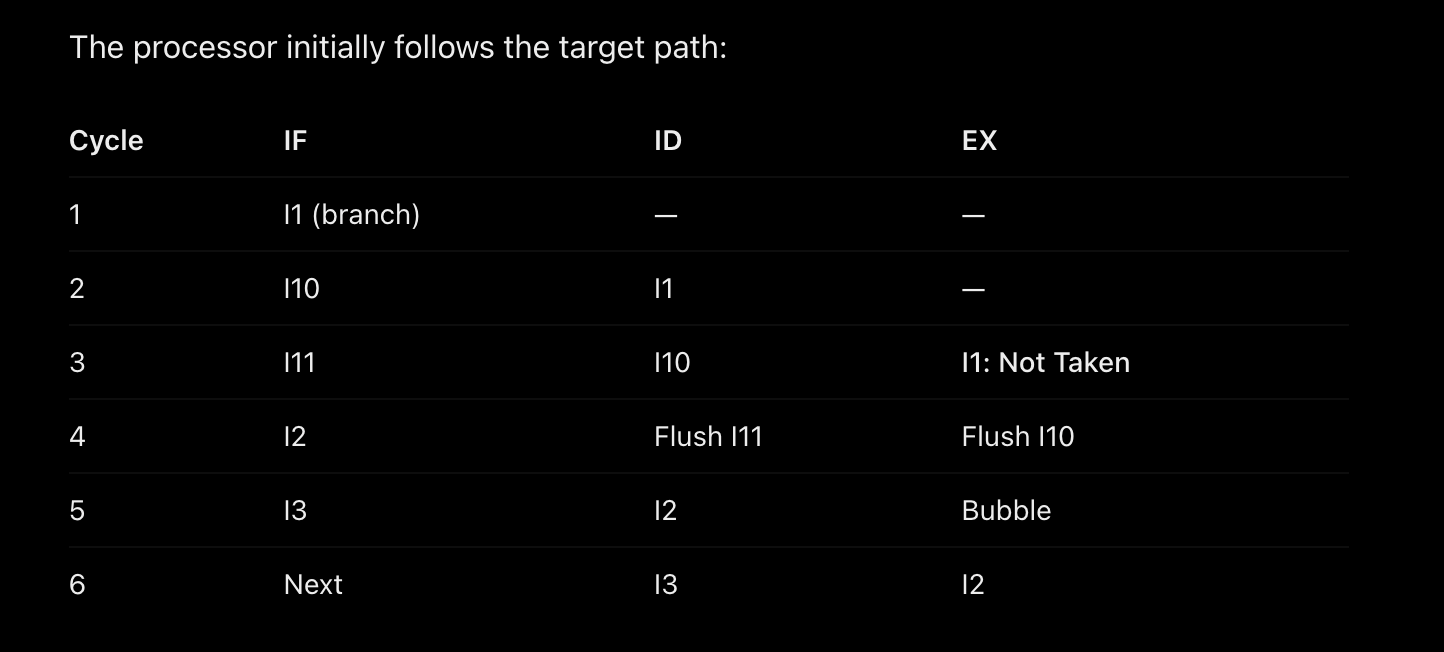

### 1.2 What Happens When the Prediction Is Wrong?

The processor discovers the wrong prediction at the **end of cycle 3**.

At that moment, I10 and I11 are wrong-path instructions.

They must be invalidated before they can change the architectural state.

The fetch unit redirects the PC to I2.

This is called **pipeline flushing**.

The wrong-path instructions occupied two pipeline slots, producing a **two-cycle misprediction penalty** in our simplified EX-resolution model.

---

## 2. Static Branch Prediction

**Professor's Video:** Approximately 64:27–66:46

> **Definition:** Static branch prediction predicts branch behavior using a predefined rule rather than learning from the branch's runtime history.

The professor discusses three approaches.

### 2.1 A. Always Taken

Predict every conditional branch as taken.

For:

```asm
beq x1, x2, TARGET
```

The processor predicts:

$$
PC_{\text{next}}=TARGET
$$

It does not wait to evaluate `x1 == x2`.

This performs well when most branches are taken, but poorly when most are not taken.

### 2.2 B. Always Not Taken

Predict that every conditional branch will fall through.

$$
PC_{\text{next}}=PC+4
$$

The processor continues fetching sequential instructions.

This can be effective for workloads with many not-taken branches.

### 2.3 C. Backward Taken, Forward Not Taken (BTFN)

The prediction depends on the direction of the branch target.

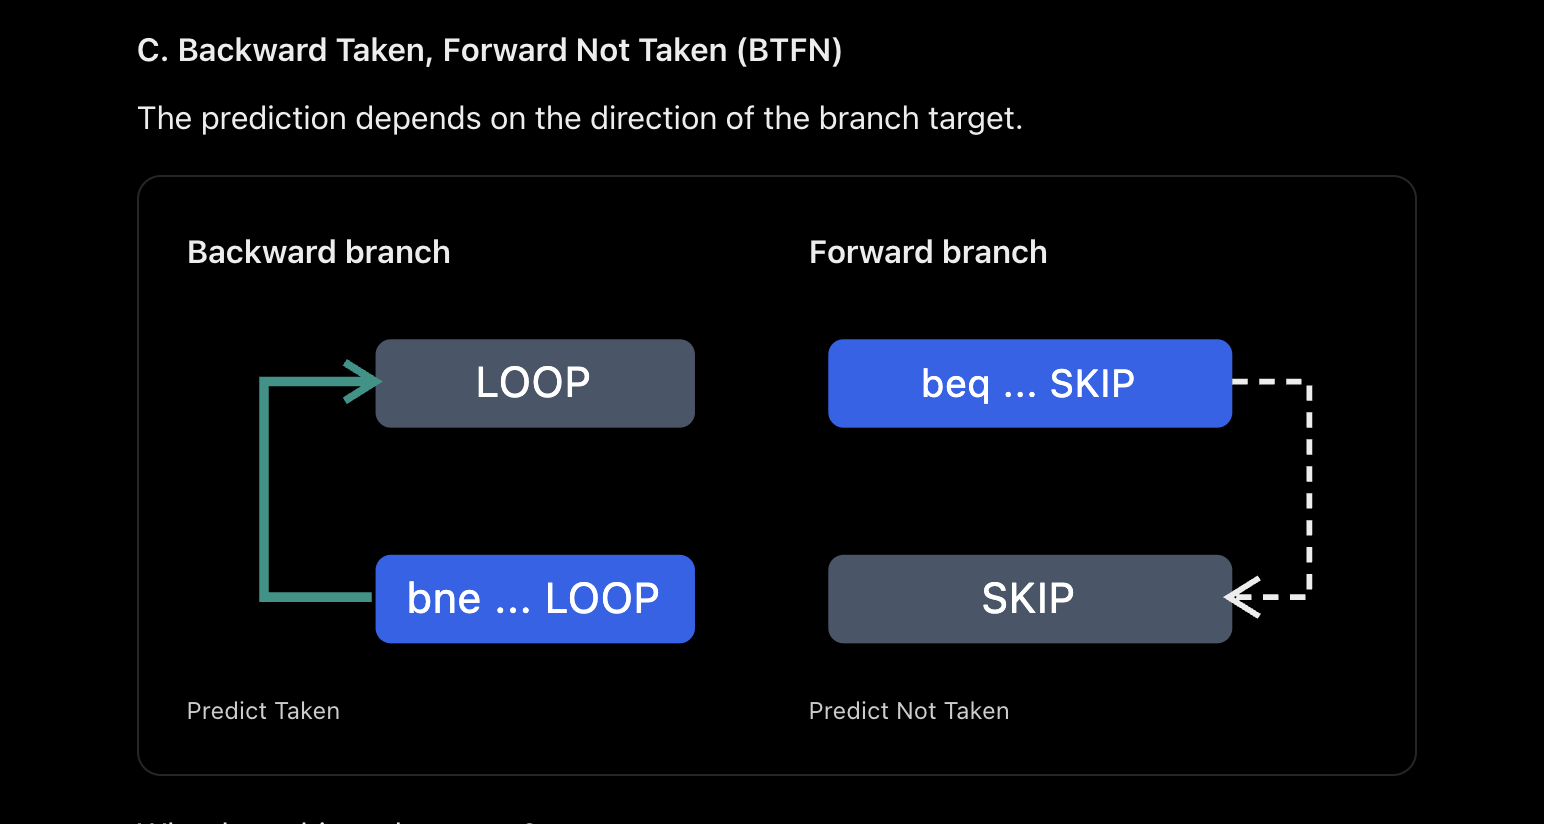

| Branch Direction | Prediction |
|---|---|
| Backward branch | **Taken** |
| Forward branch | **Not Taken** |

### Why Does This Make Sense?

A backward branch commonly represents a loop:

```asm
LOOP:
    addi x5, x5, -1
    bne  x5, x0, LOOP
```

If `x5` starts at 5, the branch outcomes are:

$$
T,\ T,\ T,\ T,\ N
$$

Here:

- `T` means Taken.
- `N` means Not Taken.

BTFN correctly predicts four of the five outcomes.

$$
\text{Accuracy}=\frac{4}{5}\times100=\boxed{80\%}
$$

This is why backward branches are often predicted as taken.

> 📌 However, branch direction is only a heuristic; not every backward branch is taken, and not every forward branch is not taken.

---

## 3. Dynamic Branch Prediction

**Professor's Video:** Approximately 66:47–68:32

> **Definition:** Dynamic branch prediction uses previous branch outcomes to predict future behavior.

Rather than always choosing the same answer, the predictor updates its state as the program executes.

The professor mentions several dynamic predictor types.

Let's understand the two fundamental ones from first principles.

### 3.1 A. One-Bit Dynamic Predictor

Imagine a predictor storing one bit for a particular branch:

$$
Prediction=
\begin{cases}
0 & \text{Not Taken}\\
1 & \text{Taken}
\end{cases}
$$

The predictor remembers the previous outcome.

After the branch executes, the bit is updated to the actual result.

### 3.2 Interactive Dry Run — Explore a One-Bit Predictor

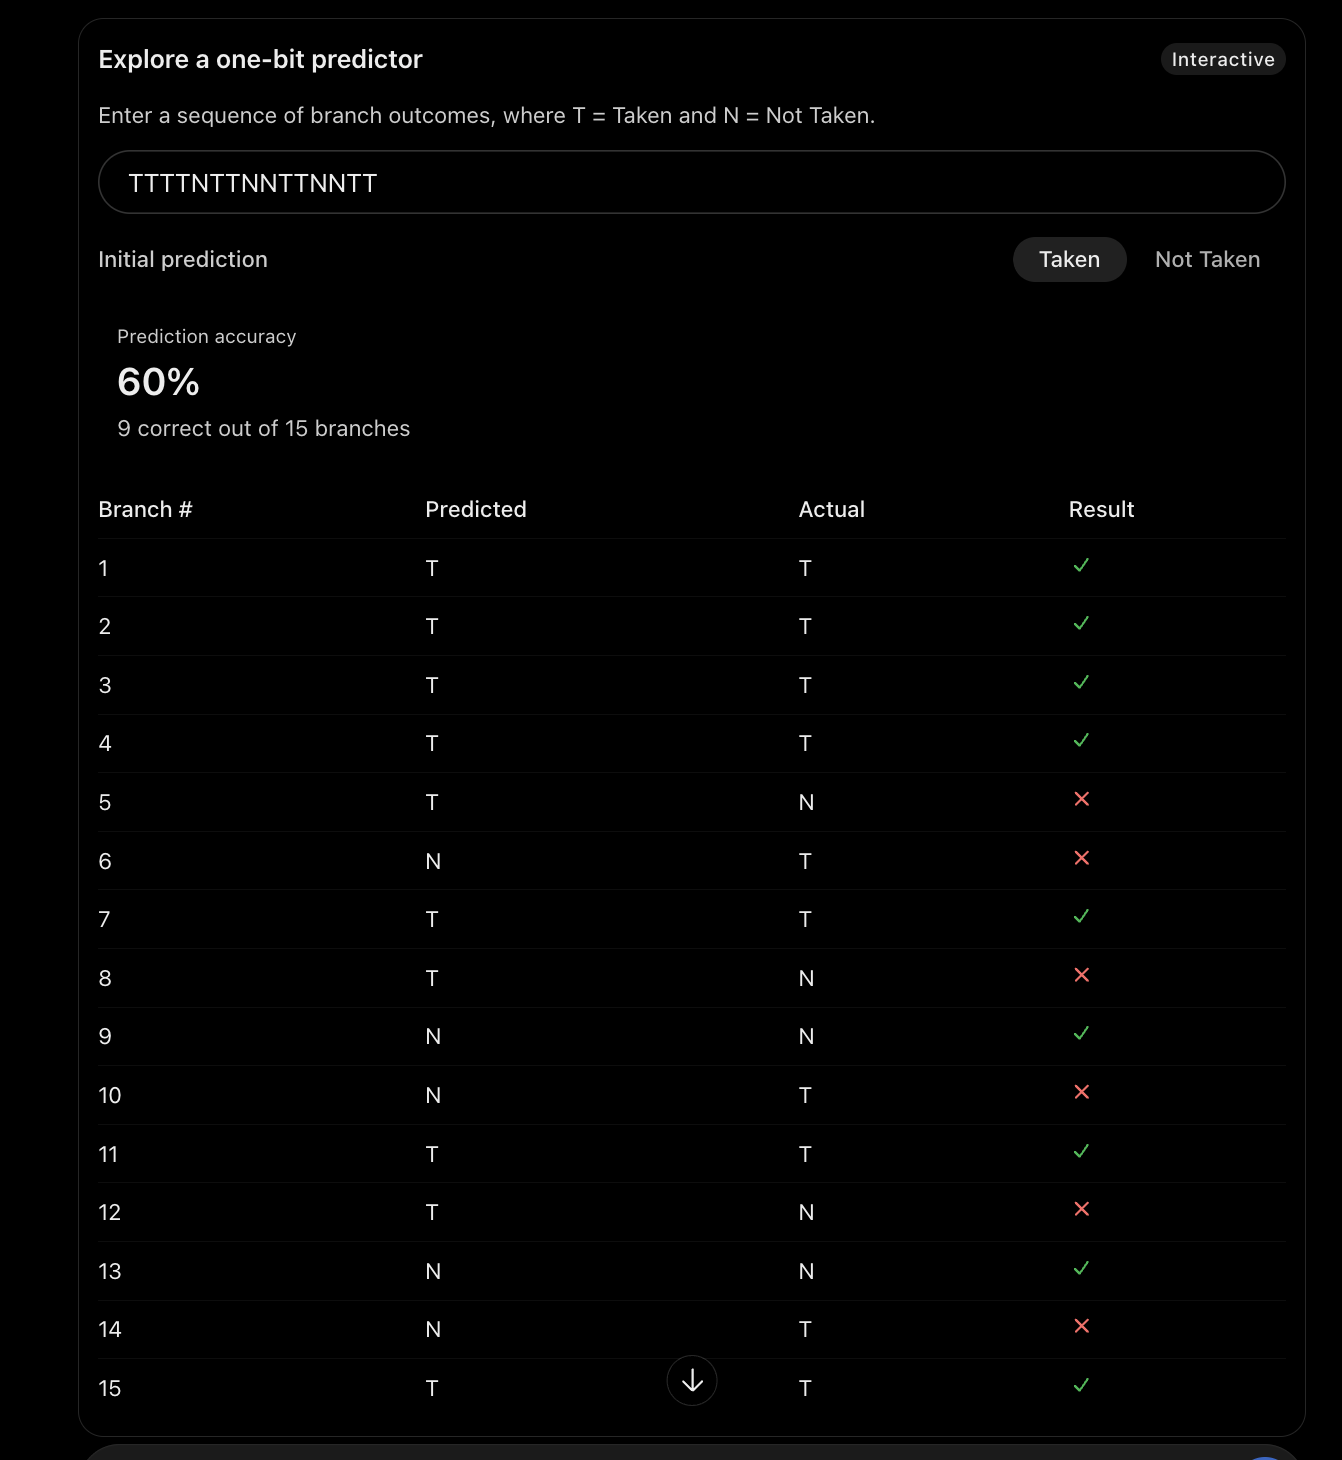
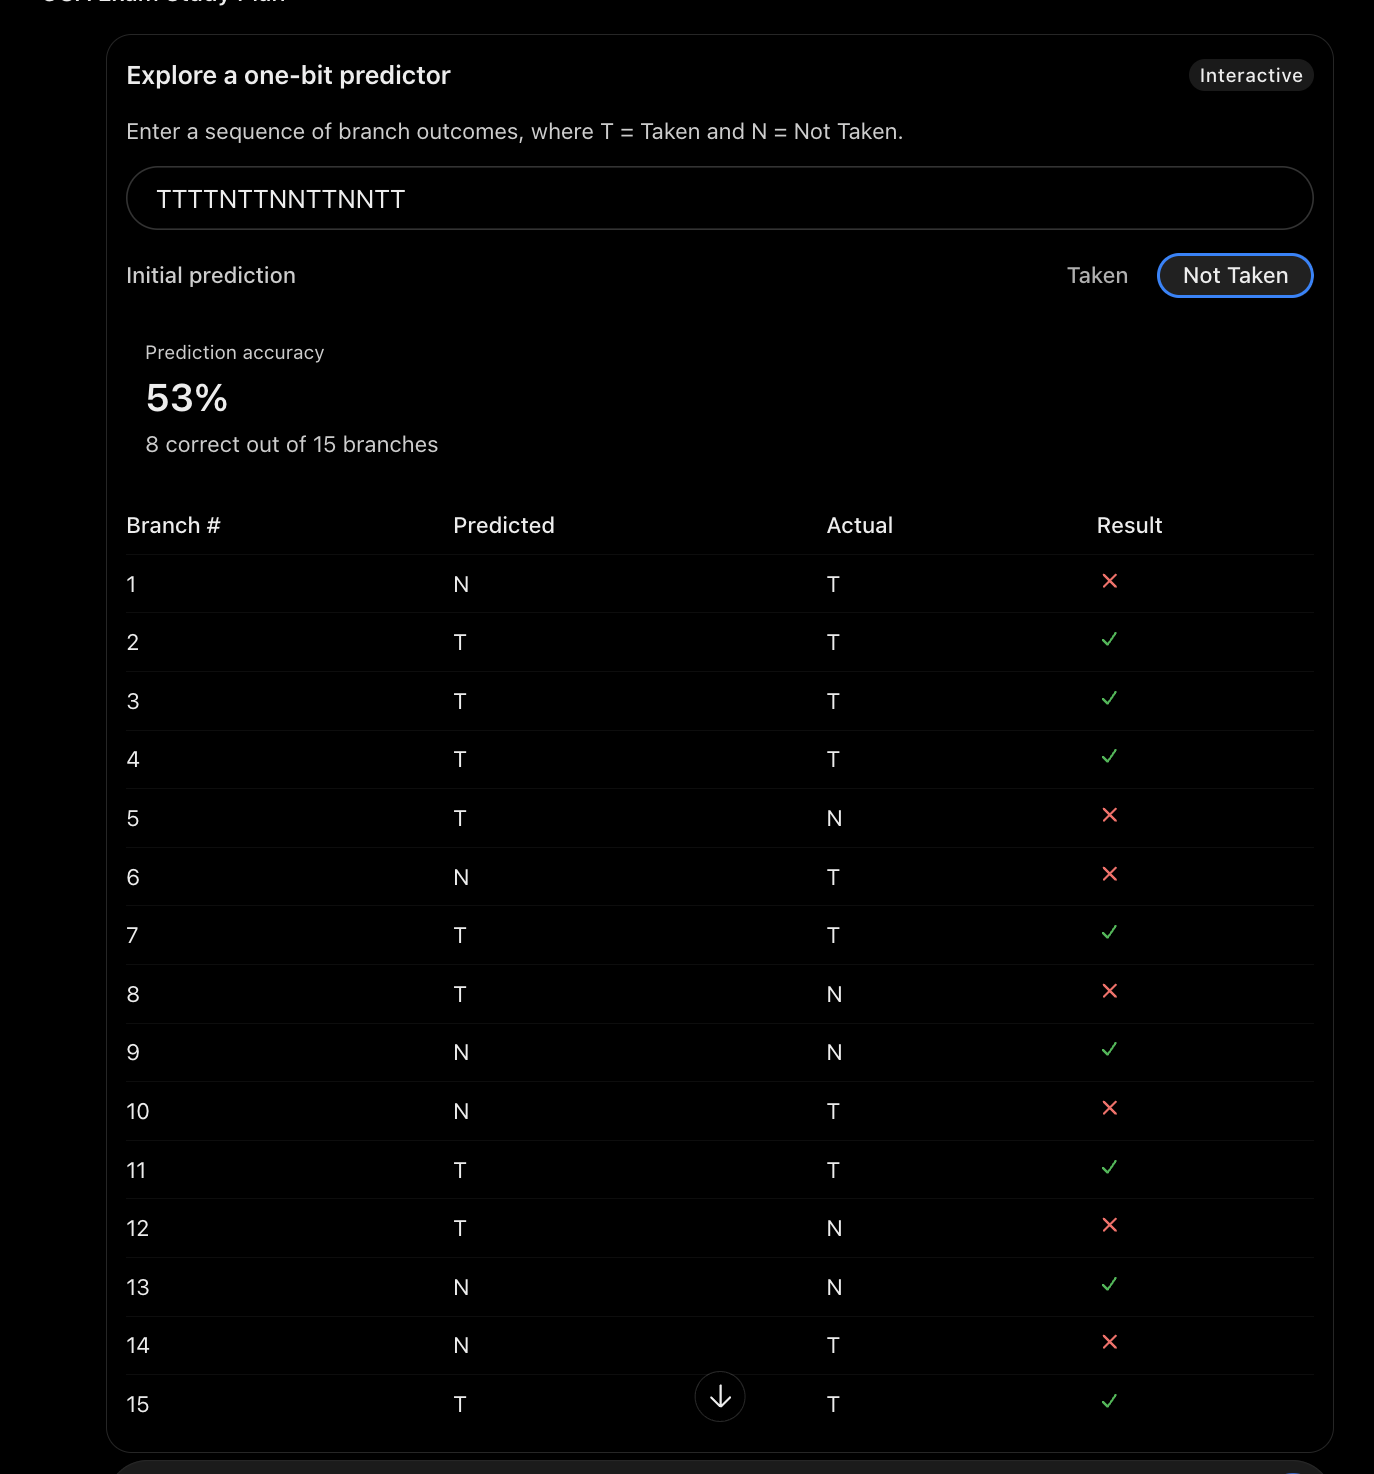

Enter a sequence of branch outcomes, where:

- `T` = Taken
- `N` = Not Taken

**Initial prediction:** Taken

**Prediction accuracy:** 70%

**7 correct out of 10 branches.**

| Branch # | Predicted | Actual | Result |
|---|---|---|---|
| 1 | T | T | Correct |
| 2 | T | T | Correct |
| 3 | T | T | Correct |
| 4 | T | T | Correct |
| 5 | T | N | Incorrect |
| 6 | N | T | Incorrect |
| 7 | T | T | Correct |
| 8 | T | T | Correct |
| 9 | T | T | Correct |
| 10 | T | N | Incorrect |

### 3.3 Weakness of a One-Bit Predictor

A one-bit predictor is simple, but it has a weakness.

Consider a loop branch:

$$
T,T,T,T,N
$$

If the predictor currently predicts Taken, it predicts the first four branches correctly.

At loop exit, the branch is Not Taken, so the prediction fails, and the bit changes to Not Taken.

The next time the loop starts, the first branch is Taken again, so the predictor makes another mistake.

**This motivates a more stable predictor.**

---

## 4. Two-Bit Saturating Counter Predictor

Instead of remembering only the last outcome, we can maintain a two-bit state.

There are four states:

| State | Binary | Prediction |
|---|---|---|
| Strongly Not Taken (SNT) | `00` | Not Taken |
| Weakly Not Taken (WNT) | `01` | Not Taken |
| Weakly Taken (WT) | `10` | Taken |
| Strongly Taken (ST) | `11` | Taken |

The predictor **increments its counter after a Taken outcome** and **decrements it after a Not Taken outcome**.

But it saturates at `00` and `11`: the counter cannot go beyond these limits.

### 4.1 State Machine

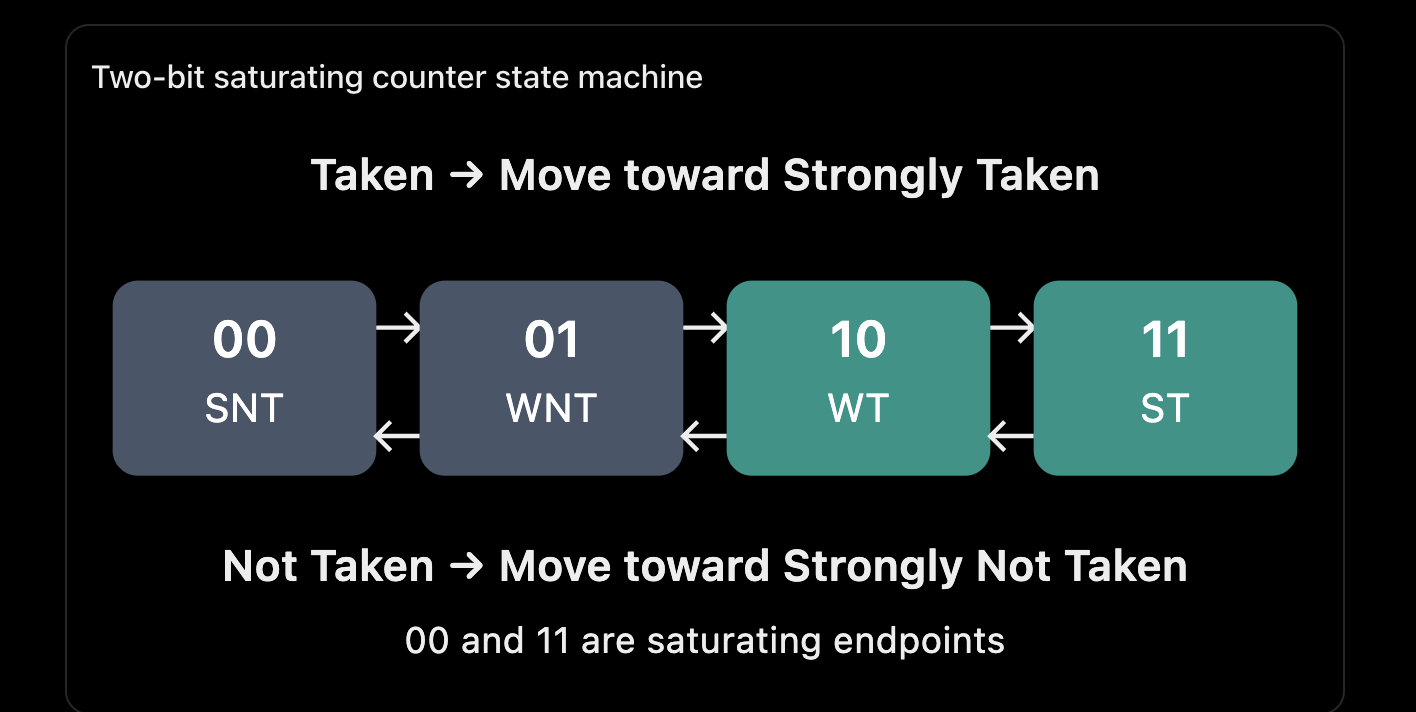
### 4.2 Why Is It Better Than a One-Bit Predictor?

Suppose the predictor is in Strongly Taken (`11`).

A single Not Taken outcome changes:

$$
11\rightarrow10
$$

The predictor moves to **Weakly Taken**, but still predicts Taken.

It generally takes **two consecutive Not Taken outcomes** to switch the prediction from Taken to Not Taken when starting in Strongly Taken.

This makes it more resistant to occasional changes in branch direction.

### 4.3 Numerical Example

Suppose the actual branch sequence is:

$$
T,T,T,N,T
$$

Start from **Strongly Taken (`11`)**.

| Branch | Initial State | Prediction | Actual | Updated State |
|---|---|---|---|---|
| 1 | ST | T | T | ST |
| 2 | ST | T | T | ST |
| 3 | ST | T | T | ST |
| 4 | ST | T | N | WT |
| 5 | WT | T | T | ST |

Only **one prediction is wrong**.

The predictor remains Taken despite the occasional Not Taken outcome.

> 💡 This is the central advantage of a two-bit saturating predictor.

---

## 5. Other Dynamic Predictors Mentioned by the Professor

The direct-video analysis also identifies these categories:

| Predictor | Basic Idea |
|---|---|
| Global predictor | Uses outcomes of recent branches to predict future branches |
| Tournament predictor | Selects between multiple prediction mechanisms |
| TAGE predictor | Uses tagged tables indexed by different history lengths |
| Hierarchical predictor | Uses multiple levels of prediction information |

These advanced mechanisms are not developed mathematically in the analyzed Lecture 27 outline.

For this lecture, you should prioritize:

- One-bit predictor
- Two-bit saturating counter
- Static vs dynamic branch prediction

---

## 6. Lecture 27 — Final Exam Revision

### 6.1 Three Solutions for Control Hazards

| Solution | Working | Main Limitation |
|---|---|---|
| Stalling | Wait until branch outcome is known | Wastes cycles |
| Delayed branching | Execute safe instructions in branch-delay slots | Difficult to find suitable instructions; ISA-dependent |
| Branch prediction | Predict next instruction address and execute speculatively | Mispredictions require flushing |

### 6.2 Important Formulas

**Stalling Penalty**

For the professor's simple five-stage EX-resolution pipeline:

$$
\boxed{\text{Stalling penalty}=2\text{ cycles}}
$$

**Correct Prediction**

$$
\boxed{\text{Prediction penalty}=0}
$$

**Misprediction**

$$
\boxed{\text{Penalty}\approx2\text{ cycles}}
$$

**Approximate Steady-State CPI**

$$
\boxed{
CPI\approx CPI_{\text{base}}+f_b\,r_m\,P_m
}
$$

Where:

- $f_b$ = Branch frequency.
- $r_m$ = Misprediction rate.
- $P_m$ = Misprediction penalty in cycles.

---
